# QC tensorial MT y sensibilidad a incertidumbre

**Pregunta:** ¿Qué permite afirmar el tensor medido cl061 si falla la condición necesaria 1D?

**Nivel 1 — Fundamentos**  
**Prerrequisitos:** nociones de Python; 35 min.



## Objetivos

Pregunta: ¿Qué diagnósticos del cl061 medido se pueden usar cuando falla su filtro tensorial necesario para 1D?



## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` es requerido por el operador directo MT.



## Datos

Registro medido solo QC y artefacto sintético de calibración separado; no mezcle estas clases de evidencia.


## Método

Clear Lake `cl061` es un conjunto medido de terreno con 42 frecuencias y verdad del subsuelo desconocida. Su recibo falla la prueba necesaria de consistencia tensorial 1D; permanece **solo para QC** y no debe ajustarse con la inversa estratificada. Esta lección aplica directamente al tensor y las incertidumbres marginales versionadas los diagnósticos implementados `mt_field_qc.tensor_gate` y `phase_tensor_diagnostic`. También inspecciona el tipper suministrado, evidencia auxiliar que nunca se usa como entrada del solver 1D.

Se conserva la rotación EDI en el marco recibido (`rotation_action: none`); no se intenta una rerrotación sin covarianza. El módulo comprueba que la distancia geométrica a un tensor 1D ideal sea invariante ante un giro de 90°, propiedad diagnóstica y no reprocesamiento de esta estación. La varianza del tipper está explícitamente sin interpretar en el recibo; por ello se grafican solo magnitudes de componentes y frecuencias faltantes. No se calculan residuos normalizados ni barras de error del tipper.

Con `exp(+iωt)`, `Z=E/H` está en Ω, la resistividad aparente `ρₐ=|Z|²/(μ₀ω)` en Ω·m, la fase en grados y el período `T=1/f` en segundos. La prueba es un nulo necesario de consistencia, no una demostración de dimensionalidad. Un fallo no se corrige ajustando una inversión 1D.
### Límite de elegibilidad de cl061

El tensor medido de 42 períodos falla filtros 1D guardado y recalculado; tensor de fase y tipper siguen como evidencia QC auxiliar.

Con la convención armónica declarada, la impedancia relaciona los campos horizontales:
$$\\mathbf{E}(f)=\\mathbf{Z}(f)\\mathbf{H}(f),\\qquad \\mathbf{Z}=\\mathbf{Z}_{re}+i\\mathbf{Z}_{im}.$$
f es frecuencia en hercios; E y H son vectores horizontales de campo eléctrico y magnético, y Z se mide en ohmios. Para la respuesta fuera de la diagonal, $$T=1/f,\\qquad \\rho_a=|Z_{ij}|^2/(\\mu_0 2\\pi f),\\qquad \\phi=\\arg(Z_{ij}).$$ T es el período en segundos, mu0 la permeabilidad del vacío, la resistividad aparente se expresa en ohmio-metro y la fase en grados. La resistividad aparente es una transformación de la respuesta, no una muestra a cierta profundidad.

El nulo 1D necesario es un tensor antisimétrico con diagonal nula. Por período, la implementación estima a=(Zxy-Zyx)/2 y calcula d=||Z-aJ||F/||Z||F, con J=[[0,1],[-1,0]] y norma de Frobenius ||.||F. Calcula además las puntuaciones normalizadas de diagonal |Zxx|/(sqrt(2)sigma_xx), |Zyy|/(sqrt(2)sigma_yy) y antisimetría |Zxy+Zyx|/(sqrt(2)(sigma_xy+sigma_yx)). Para la puntuación s_k del período k, WRMS=sqrt(mean_k(s_k^2)). Contribuyen todos los períodos suministrados. Usar la suma de desviaciones marginales es una política declarada y conservadora; no existe covarianza entre componentes para construir un estadístico Mahalanobis completo.

El tensor de fase resuelve Re(Z)Phi=Im(Z) mediante un sistema lineal. Es auxiliar: su condicionamiento y desviación escalar no cambian el filtro de impedancia ni demuestran una geología.

El tensor contiene cuatro funciones complejas de transferencia por frecuencia, pero la pregunta QC es más acotada que recuperar un modelo de conductividad. Los términos diagonales y la parte simétrica del par fuera de diagonal se apartan de la forma 1D. Sus puntuaciones normalizadas por ruido preguntan si esas desviaciones son grandes respecto de los errores marginales informados. El umbral almacenado es 3 para cada WRMS. El código informa cada puntuación, el uso de todos los períodos, la máscara de origen y una distancia geométrica invariante ante un cuarto de vuelta. Esta última comprobación protege una propiedad matemática; no corrige el marco de adquisición.

Las curvas de resistividad aparente y fase se mantienen separadas por orientación, porque promediar XY e YX puede ocultar una discrepancia real. El eje horizontal usa período, ordenado de forma creciente para interpretación; cada valor conserva su índice del registro de origen. El escalar del tensor de fase y la magnitud del tipper usan ejes separados porque sus unidades y significados difieren. Faltan dos períodos del tipper y su varianza no está interpretada, así que no se justifica interpolar ni dibujar barras de incertidumbre. Si el cálculo del tensor de fase omite una matriz real mal condicionada, esos períodos deben informarse; no se debe dibujar una curva continua sin indicarlo.

Interprete el resultado como una decisión de elegibilidad para un flujo estratificado específico. El registro cl061 de Clear Lake es medido, contiene 42 períodos y no tiene verdad del subsuelo conocida en este ejercicio. Tanto el filtro persistido como el recálculo fallan. No ejecute la inversión estratificada con ese registro ni convierta el fallo en una afirmación de que los datos carecen de utilidad: aún sirven para QC y pueden motivar un modelo de otra dimensionalidad. Aprobar solo permitiría la siguiente prueba controlada; no demostraría geología 1D. La calibración sintética separada prueba el software y no representa a la estación.


In [1]:
# Aplicar diagnósticos QC implementados al tensor medido; no ajustar cl061.
import json, sys
from pathlib import Path
import numpy as np
from importlib.metadata import version

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from mt_field_qc import tensor_gate, phase_tensor_diagnostic

case = json.loads((root / "data/derived/v2/edi/clear-lake-cl061-screen.json").read_text(encoding="utf-8"))
f = np.asarray(case["frequencies_hz"], float)
period = 1 / f
z = np.asarray(case["tensor"]["real"]) + 1j * np.asarray(case["tensor"]["imag"])
sigma = np.asarray(case["tensor"]["sigma"], float)
gate = tensor_gate(z, sigma**2)  # El recibo guarda SD marginal; la función QC recibe varianza.
phase_qc = phase_tensor_diagnostic(z)
tip = case["metadata"]["tipper"]
print("Versiones:", {name: version(name) for name in ("numpy", "matplotlib", "scipy")})
print("Fuente medida:", case["id"], case["source_kind"], "N=", len(f), "verdad=", case['truth'])
print(
    "Elegibilidad:",
    case["one_d_inversion_eligible"],
    "prueba guardada:",
    case["compatibility"]["passes_screen"],
    "recalculada:",
    gate["passes"],
)
print("Puntajes QC:", list(gate["per_period_normalized"]), "límite:", gate['threshold'])
print("Error máx. de invariancia geométrica al cuarto de giro:", gate["quarter_turn_invariance_max_abs_error"])


Versiones: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
Fuente medida: cl061 measured EDI transfer functions N= 42 verdad= None
Elegibilidad: False prueba guardada: False recalculada: False
Puntajes QC: ['xx', 'yy', 'antisymmetry'] límite: 3.0
Error máx. de invariancia geométrica al cuarto de giro: 1.1102230246251565e-16


### Inspeccionar diagnósticos de tensor de fase y tipper

La compuerta invariante de impedancia informa por separado sus puntajes por período y la elegibilidad. Aquí se muestran los campos del tensor de fase y del tipper; no cambian el estado QC-only de Clear Lake.

In [2]:
# Inspeccionar diagnósticos de tensor de fase y tipper.
print(
    "Períodos utilizables del tensor de fase:",
    phase_qc["usable_periods"],
    "desviación escalar mediana:",
    phase_qc["median_scalar_departure"],
)
print(
    "Tipper presente:",
    tip["present"],
    "usado por inversa 1D:",
    tip["used_in_1d_inversion"],
    "varianza:",
    tip["raw_variance_convention"],
)


Períodos utilizables del tensor de fase: 42 desviación escalar mediana: 0.257651139958079
Tipper presente: True usado por inversa 1D: False varianza: uninterpreted EDI native variance


### Diagnóstico 2 — Recalcular QC tensorial e inspeccionar el tipper auxiliar

El panel superior derecho muestra las tres verificaciones necesarias de 1D normalizadas por ruido. La superposición inferior derecha presenta desviación escalar del tensor de fase y magnitud bruta del tipper; son indicios QC, no objetivos de una inversa 1D. Los períodos faltantes del tipper siguen faltantes.

Grafique primero impedancia y compuerta de consistencia 1D; luego agregue tensor de fase y diagnóstico del tipper.

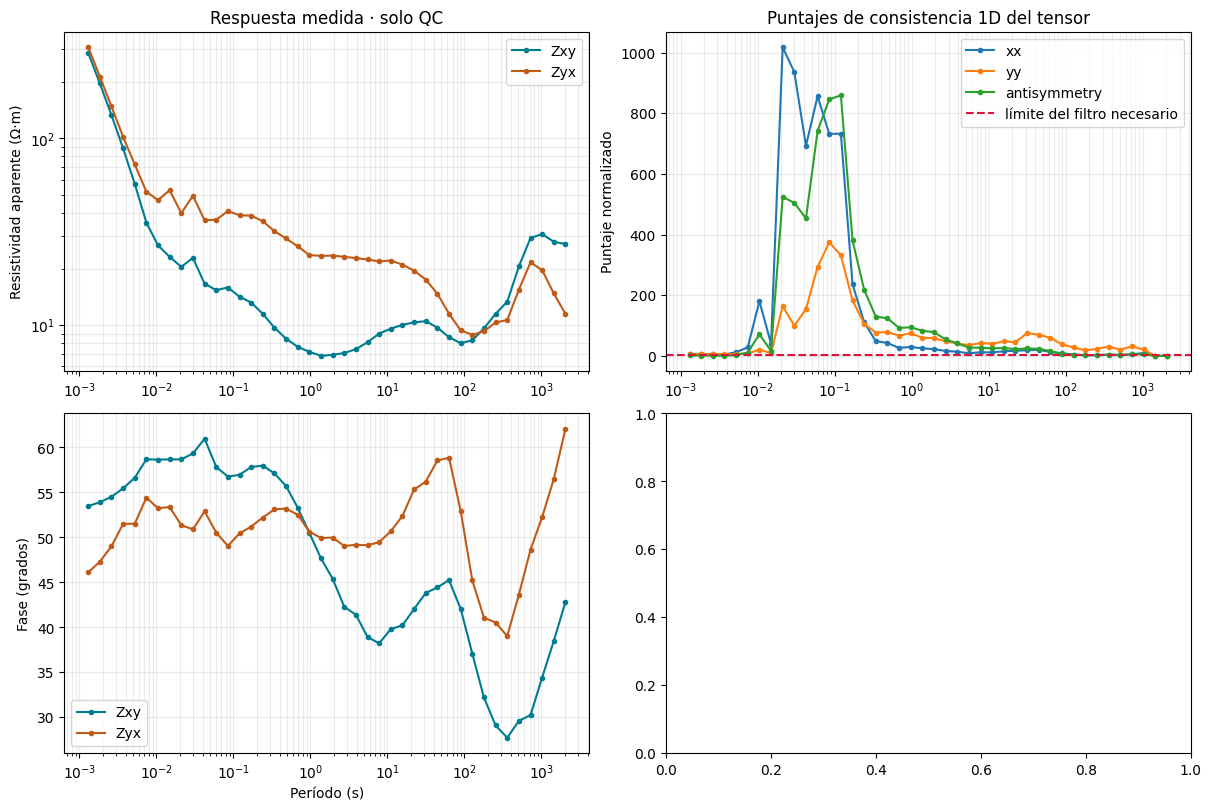

In [3]:
# Grafique la impedancia y la condición necesaria de tensor 1D.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for name, color in (("xy", "#007c91"), ("yx", "#bf5b17")):
    response = case["observed"][name]
    ax[0, 0].loglog(period, response["apparent"], ".-", label="Z" + name, color=color)
    ax[1, 0].semilogx(period, response["phase"], ".-", label="Z" + name, color=color)
ax[0, 0].set_ylabel("Resistividad aparente (Ω·m)")
ax[1, 0].set_ylabel("Fase (grados)")
ax[1, 0].set_xlabel("Período (s)")
for axis in (ax[0, 0], ax[1, 0]):
    axis.grid(True, which="both", alpha=0.25)
    axis.legend()
ax[0, 0].set_title("Respuesta medida · solo QC")
for key, score in gate["per_period_normalized"].items():
    ax[0, 1].semilogx(period, score, ".-", label=key)
ax[0, 1].axhline(gate['threshold'], color="crimson", ls="--", label="límite del filtro necesario")
ax[0, 1].set_title("Puntajes de consistencia 1D del tensor")
ax[0, 1].set_ylabel("Puntaje normalizado")
ax[0, 1].legend()
ax[0, 1].grid(True, which="both", alpha=0.25)


El primer panel compara ambas orientaciones de impedancia medida y la compuerta necesaria 1D. La siguiente celda agrega desviación del tensor de fase y magnitudes crudas del tipper; su varianza no tiene interpretación declarada y no se convierte en incertidumbre.

In [4]:
# Añada diagnósticos del tensor de fase y magnitudes brutas del tipper sin interpretar su varianza.
pt = phase_qc["per_period"]
pt_period = np.asarray([period[row["source_index"]] for row in pt])
pt_departure = np.asarray([row["scalar_departure"] for row in pt])
ax[1, 0].set_title("Respuesta de fase medida")
ax[1, 1].semilogx(pt_period, pt_departure, "o", ms=4, color="#7651a8")
ax[1, 1].set_title("Desviación escalar del tensor de fase")
ax[1, 1].set_ylabel("Relative departure (dimensionless)")
ax[1, 1].set_xlabel("Período (s)")
ax[1, 1].grid(True, which="both", alpha=0.25)
tx = np.asarray(tip["components"]["X"]["real"], dtype=float)
tx = tx + 1j * np.asarray(tip["components"]["X"]["imag"], dtype=float)
ty = np.asarray(tip["components"]["Y"]["real"], dtype=float)
ty = ty + 1j * np.asarray(tip["components"]["Y"]["imag"], dtype=float)
axis = ax[1, 1].twinx()
axis.semilogx(period, np.abs(tx), "s", ms=3, color="#007c91", alpha=0.65, label="|Tx|")
axis.semilogx(period, np.abs(ty), "^", ms=3, color="#bf5b17", alpha=0.65, label="|Ty|")
axis.set_ylabel("Magnitud del tipper (adimensional)")
handles, labels = ax[1, 1].get_legend_handles_labels()
tipper_handles, tipper_labels = axis.get_legend_handles_labels()
axis.legend(handles + tipper_handles, labels + tipper_labels, fontsize=8, loc="best")
fig.suptitle("Evidencia medida Clear Lake cl061 — solo QC; sin ajuste estratificado")
plt.show()
print("Frecuencias faltantes del tipper (Hz):", tip["missing_frequency_hz"])
print("La varianza del tipper no está interpretada; no se muestran barras de incertidumbre del tipper.")


Frecuencias faltantes del tipper (Hz): [0.0004882812, 0.0006915263]
La varianza del tipper no está interpretada; no se muestran barras de incertidumbre del tipper.


### Sensibilidad a la incertidumbre por componente

La decisión es un filtro necesario bajo la incertidumbre entregada con el EDI, no una probabilidad de que la Tierra sea unidimensional. Multiplicar todas las desviaciones estándar de componente por c solo cambia la normalización de las puntuaciones; tensor, períodos y máscaras permanecen fijos. El barrido usa 49 valores logarítmicos de c entre 0,25 y 4 y el límite declarado de puntuación 3. Pregunta cuánto cambiarían los diagnósticos bajo un reescalamiento uniforme hipotético. El resultado adoptado sigue siendo c=1. Cruzar el límite con otro c es evidencia de sensibilidad, no una nueva decisión de elegibilidad ni un argumento para alterar errores medidos.

No se puede excluir un período porque resulte incómodo para el promedio: contribuyen todas las frecuencias suministradas. El siguiente gráfico conserva cada puntuación por período para que un intervalo breve no desaparezca dentro del WRMS. La puntuación no tiene dimensión y el eje logarítmico es el período en segundos; ni el color ni la posición de la curva son resistividad del subsuelo. Lea esta vista junto al resumen y al recibo de datos faltantes.

In [5]:
# Recalcule la prueba necesaria con desviaciones estándar dobles.
looser_gate = tensor_gate(z, (2 * sigma) ** 2)
print("WRMS con 2× sigma:", looser_gate["wrms"])


WRMS con 2× sigma: {'xx': 160.11663013231475, 'yy': 54.753939889373655, 'antisymmetry': 133.80001937595154}


### Sensibilidad por frecuencia y puntuación QC

Esta vista adicional se genera con el mismo tensor medido; no es un modelo de resistividad. Recalcule con la mitad de desviación para mostrar sensibilidad QC.

In [6]:
# Recalcule con la mitad de desviación para mostrar sensibilidad QC.
tighter_gate = tensor_gate(z, (0.5 * sigma) ** 2)
print("WRMS con 0,5× sigma:", tighter_gate["wrms"])


WRMS con 0,5× sigma: {'xx': 640.466520529259, 'yy': 219.01575955749462, 'antisymmetry': 535.2000775038061}


### Barrido de incertidumbre del tensor medido

Solo cambia el multiplicador de incertidumbre. Los 42 períodos siguen en cada cálculo.

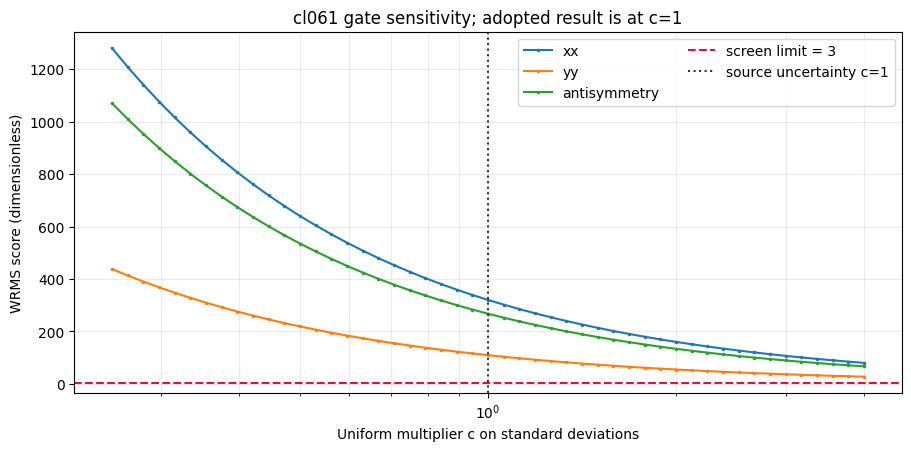

Adopted decision at c=1: False (the sweep does not change it)


In [7]:
# Recompute the same QC gate over a controlled multiplicative uncertainty sweep.
scales = np.geomspace(0.25, 4.0, 49)
score_names = tuple(gate["wrms"])
score_curves = {name: [] for name in score_names}
for scale in scales:
    trial = tensor_gate(z, (scale * sigma) ** 2)
    for name in score_names:
        score_curves[name].append(trial["wrms"][name])
fig_sweep, ax_sweep = plt.subplots(figsize=(9, 4.4), constrained_layout=True)
for name, values in score_curves.items():
    ax_sweep.semilogx(scales, values, marker=".", ms=3, label=name)
ax_sweep.axhline(gate["threshold"], color="crimson", ls="--", label="screen limit = 3")
ax_sweep.axvline(1.0, color="#333333", ls=":", label="source uncertainty c=1")
ax_sweep.set(xlabel="Uniform multiplier c on standard deviations",
             ylabel="WRMS score (dimensionless)", title="cl061 gate sensitivity; adopted result is at c=1")
ax_sweep.grid(True, which="both", alpha=0.25)
ax_sweep.legend(ncol=2)
plt.show()
print("Adopted decision at c=1:", gate["passes"], "(the sweep does not change it)")


La línea horizontal es el umbral fijo; la vertical marca la incertidumbre del registro fuente. Las curvas muestran sensibilidad diagnóstica, no resultados alternativos aceptados.

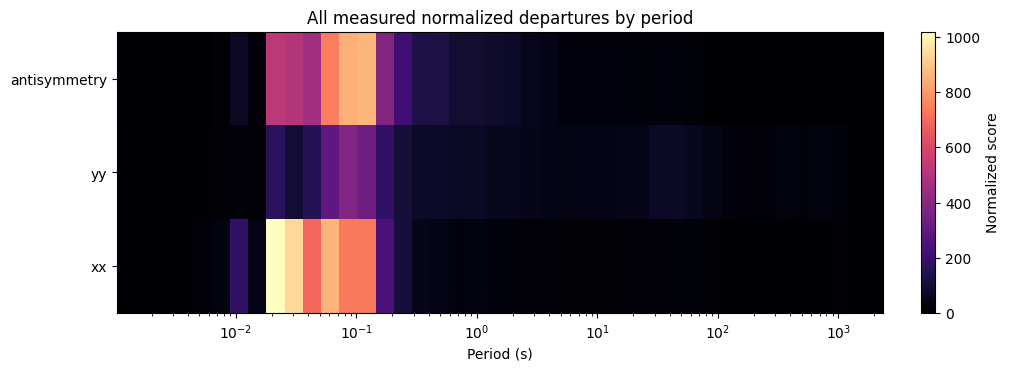

In [8]:
# Plot all supplied periods on a logarithmic axis; do not drop any rows.
score_matrix = np.vstack([gate["per_period_normalized"][name] for name in score_names])
fig_period, ax_period = plt.subplots(figsize=(10, 3.6), constrained_layout=True)
image = ax_period.pcolormesh(period, np.arange(len(score_names)) + 0.5, score_matrix,
                             shading="auto", cmap="magma", vmin=0)
ax_period.set_xscale("log")
ax_period.set_yticks(np.arange(len(score_names)) + 0.5, score_names)
ax_period.set_xlabel("Period (s)")
ax_period.set_title("All measured normalized departures by period")
fig_period.colorbar(image, ax=ax_period, label="Normalized score")
plt.show()


### Úsalo con tus propios datos EDI

La función tensor_gate no es un analizador EDI. Primero usa el adaptador de modalidad para analizar y validar el archivo, conservando identidad de estación, coordenadas, marco, orden de componentes y frecuencias, máscaras de origen, varianzas y procedencia. La función requiere un tensor NumPy complejo y finito con forma (n_frequency,2,2), y un arreglo de varianzas finitas, estrictamente positivas y de la misma forma. Rechaza tensores vacíos, de norma cero o mal formados. El vector de períodos separado debe ser positivo y alinearse fila a fila. Si el contrato de origen entrega desviaciones estándar, elévalas al cuadrado una vez al construir el argumento de varianza; no vuelvas a elevar una varianza.

La llamada mínima del producto es tensor_gate(z, sigma**2), como se ejecuta arriba. Sustituye los arreglos de ejemplo solo después de verificar unidades, orientación y alineación de filas en el recibo del analizador. Conserva en el resultado QC los WRMS, arreglos normalizados por período, umbral, bandera de aprobación, bandera de uso de todos los períodos, política de incertidumbre y error de rotación. Vincula ese resultado al hash del archivo original y a la versión del analizador. Un booleano separado de su origen y marco no se puede reproducir ni revisar.

Antes de usar el resultado, confirma por separado frecuencias positivas y finitas, dimensiones coincidentes y ausencia de eliminación silenciosa de filas. Compara el resultado recalculado con la decisión almacenada. Conserva ambos si discrepan y rastrea la transformación exacta que difiere. phase_tensor_diagnostic es independiente: resuelve Re(Z)Phi=Im(Z) solo para matrices reales suficientemente condicionadas e informa períodos omitidos. No rescata un filtro fallido. El tipper tampoco entra en esta prueba 1D.

Para desplegar este método en otro conjunto, añade un control analítico de semiespacio 1D y un control negativo deliberadamente multidimensional; prueba varianzas mal formadas y orden de componentes; y prueba rotación solo con una covarianza transformada físicamente válida. Esta lección no ajusta umbrales con cl061. El derivado USGS sigue siendo medido y solo-QC; el control sintético continúa siendo una prueba de software independiente.

### Lee un filtro fallido sin inferir geología

El filtro es una regla conservadora de admisión para una inversión 1D concreta, no una calificación general de calidad de datos. Usa tres desviaciones separadas para que una puntuación diagonal baja no oculte una antisimetría alta, e informa cada WRMS en vez de reducir toda evidencia a un escalar opaco. Un residual normalizado máximo de un solo período aún puede esconderse en el promedio; por eso el producto conserva valores por período y esta lección los grafica.

El mismo tensor observado se somete a cada multiplicador de incertidumbre del gráfico de sensibilidad. Solo cambia el denominador. Si una curva cruza el umbral por encima de uno, la implicación es condicional: el filtro cambiaría bajo errores supuestos mayores. No demuestra que los errores reales sean demasiado pequeños ni autoriza inflarlos hasta que la inversión sea elegible. Revisa la incertidumbre solo con un modelo de error justificado de manera independiente y mantén inmutable el registro original.

La prueba de cuarto de vuelta en tensor_gate compara la distancia tensorial relativa al nulo 1D antes y después de una rotación firmada de ejes. Es un invariante útil: un cambio de etiquetas de coordenadas no debería alterar esa distancia escalar. Las puntuaciones tienen su propia política de incertidumbre por componente, por lo que este invariante geométrico no significa que todas las varianzas o diagnósticos de fase sean plenamente invariantes a rotación. Para ampliar el adaptador aún se necesitan pruebas de permutación de componentes, covarianza de errores y metadatos del marco. Bajo la regla predeclarada actual, cl061 sigue siendo solo-QC.

## Resultados

El conjunto permanece solo-QC porque falla el filtro de elegibilidad 1D; sus diagnósticos de tensor y tipper no son una inversión estratificada. Los períodos faltantes del tipper siguen faltantes.

**Respuesta:** Los 42 períodos de impedancia están disponibles para el cálculo del tensor de fase, cuya desviación escalar mediana es 0.257651. Fallan tanto el filtro guardado como la elegibilidad 1D recalculada; faltan dos frecuencias de tipper y su incertidumbre no está interpretada.


## Resumen

Este EDI medido solo permite revisión QC. El filtro fallido excluye cl061 de la inversión 1D; ni la desviación del tensor de fase ni la cobertura incompleta de tipper revierten esa decisión o aportan verdad del subsuelo.



## Referencias

- [Caldwell, Bibby y Brown (2004), The magnetotelluric phase tensor, DOI 10.1111/j.1365-246X.2004.02281.x](https://doi.org/10.1111/j.1365-246X.2004.02281.x)
- [MTpy v2, software y documentación](https://github.com/MTgeophysics/mtpy-v2)
- [Datos magnetotelúricos USGS de Clear Lake](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)
- [Producto de estación cl061 de EarthScope/USGS](https://data.earthscope.org/app/products/portal/emtf/emtf_item.html?p=2022%2FMT_TF_USGS-GMEG.2022.cl061)
- [Kirkby et al. (2019), software MTPy, DOI JOSS 10.21105/joss.01358](https://doi.org/10.21105/joss.01358)